# Exploratory Data Analysis — Customer Churn
Interactive companion to `src/visualization/eda_report.py`. Run top to bottom.
All business insights are written after each chart, matching the deliverable a Data Analyst would hand to a stakeholder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
%matplotlib inline

df = pd.read_csv('../data/processed/telecom_customers_features.csv')
df.shape

(12000, 35)

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,CustomerLifecycleStage,ContractDurationMonths,IsAutoPay,SupportTicketsPerTenureYear,TotalAddOnServices,HasInternetNoProtection,CustomerValueScore,IsHighValueCustomer,IsMultiServiceHousehold,ChurnFlag
0,CUST-104767,Female,0,Yes,No,63.0,Yes,No,Fiber optic,No,...,Veteran (49mo+),1,1,0.380952,1,1,50.67,1,0,1
1,CUST-108968,Female,0,Yes,No,2.0,Yes,No,No,No internet service,...,New (0-6mo),1,0,1.000000,0,0,6.52,0,0,1
2,CUST-101139,Female,0,No,Yes,1.0,Yes,No,DSL,No,...,New (0-6mo),1,0,3.000000,3,1,19.25,0,1,1
3,CUST-102372,Male,1,No,No,3.0,Yes,Yes,No,No internet service,...,New (0-6mo),1,0,2.000000,0,0,9.89,0,0,0
4,CUST-107899,Male,0,No,No,66.0,Yes,Yes,Fiber optic,Yes,...,Veteran (49mo+),12,0,0.363636,1,0,57.79,1,0,1


## Churn Distribution

In [3]:
df['Churn'].value_counts(normalize=True).mul(100).round(1)

Churn
Yes    60.4
No     39.6
Name: proportion, dtype: float64

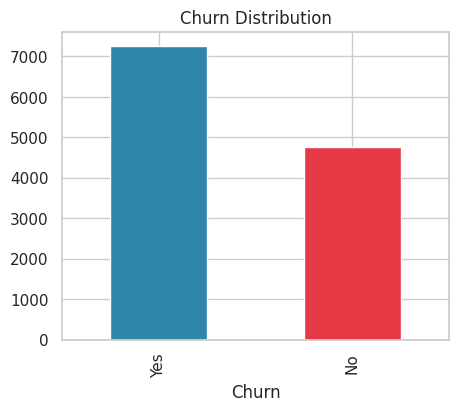

In [4]:
fig, ax = plt.subplots(figsize=(5,4))
df['Churn'].value_counts().plot(kind='bar', color=['#2E86AB','#E63946'], ax=ax)
ax.set_title('Churn Distribution'); plt.show()

**Insight:** Establishes the baseline churn rate the ML model must beat, and confirms class imbalance -- accuracy alone will be a misleading metric for evaluation.

## Churn by Contract Type

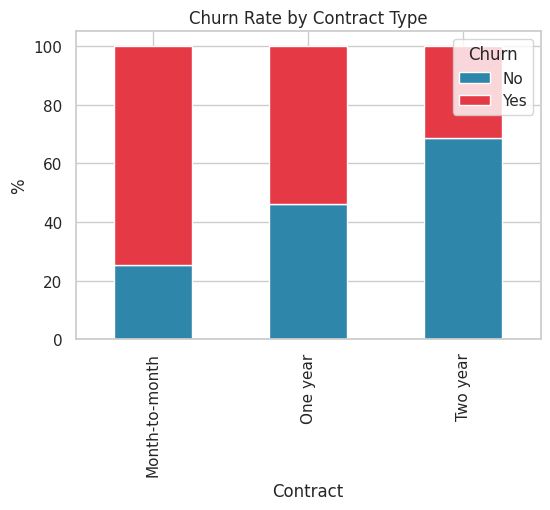

Churn,No,Yes
Contract,,
Month-to-month,25.395859,74.604141
One year,46.135097,53.864903
Two year,68.632812,31.367188


In [5]:
ct = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
ct.plot(kind='bar', stacked=True, figsize=(6,4), color=['#2E86AB','#E63946'])
plt.title('Churn Rate by Contract Type'); plt.ylabel('%'); plt.show()
ct

**Insight:** Month-to-month contracts churn far more than annual/two-year commitments. This is the strongest single retention lever available to the business.

## Correlation Matrix

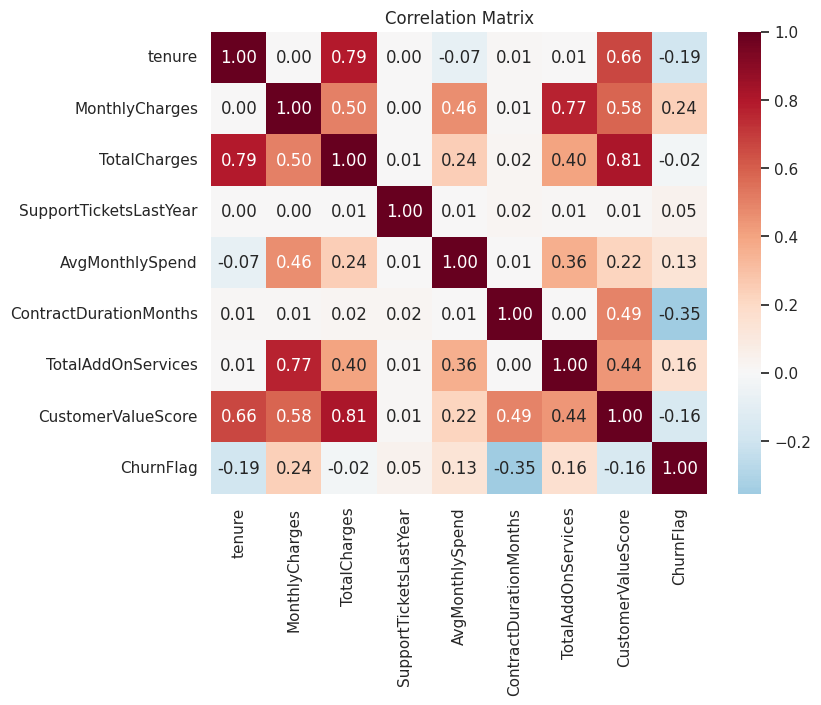

In [6]:
numeric_cols = ['tenure','MonthlyCharges','TotalCharges','SupportTicketsLastYear',
                'AvgMonthlySpend','ContractDurationMonths','TotalAddOnServices',
                'CustomerValueScore','ChurnFlag']
corr = df[numeric_cols].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation Matrix'); plt.show()

**Insight:** Tenure and contract duration are the strongest negative correlates of churn; monthly charges is a positive correlate. These guide feature selection in ModelTraining.ipynb.

## Tenure vs Churn

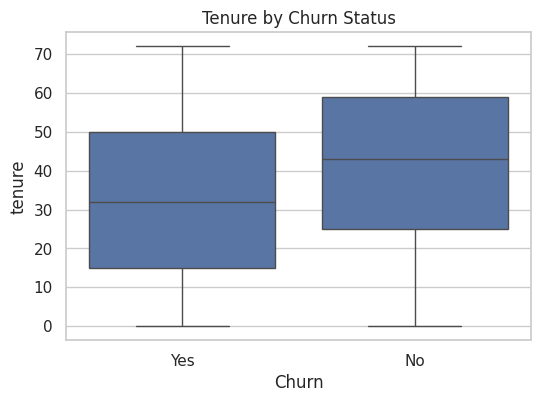

In [7]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='Churn', y='tenure')
plt.title('Tenure by Churn Status'); plt.show()

**Insight:** Churned customers cluster at low tenure. The first 12 months are the highest-risk window for this business -- see Business_Recommendations.md for the resulting onboarding-focused retention strategy.

Full chart set (10 total) and business writeups: see `reports/EDA_Report.md`.